In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly
import plotly.graph_objs as go
import seaborn as sns
import shap
from catboost import CatBoostRegressor
from data_profiling import ProfileReport
from plotly.subplots import make_subplots
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

plotly.io.renderers.default = "notebook"
%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


# Table of Contents
1. [Feature Descriptions and Profiling](#Feature-Descriptions-and-Profiling)
2. [Time Series Vizual Analysis](#Time-Series-Vizual-Analysis)
3. [Feature Dependency Analysis](#Feature-Dependency-Analysis)
4. [Data Cleaning and Grouping](#Data-Cleaning-and-Grouping)
5. [What we achieved and what is the problem](#What-we-achieved-and-what-is-the-problem)
6. [Mahalanobis distance study to identify anomaly region](#Mahalanobis-distance-study-to-identify-anomaly-region)
7. [Noise study](#Noise-study)
8. [Conclusions](#Conclusions)

# Feature Descriptions and Profiling

In [2]:
df = pd.read_parquet("../data/01_raw/df_train_test.parquet")

In [3]:
df.shape

(70000, 14)

In [4]:
df.head(3)

,Timestamps,WindSpeed,WindDirAbs,WindDirRel,Power,Pitch,GenRPM,RotorRPM,EnvirTemp,NacelTemp,GearOilTemp,GearBearTemp,GenPh1Temp,GenBearTemp
0,2007-07-29 03:10:00,4.790142,307.5,1.8,520.300000,-1.483813,1078.376427,16.229237,17.866438,59.882623,58.059329,49.079118,79.193312,51.0
1,2007-07-29 03:20:00,4.285207,312.5,2.2,564.700000,1.831067,841.497573,16.686210,21.404675,15.233595,46.598905,45.249571,95.670331,52.0
2,2007-07-29 03:30:00,7.143066,304.4,-4.9,1632.407112,-4.402055,1022.534164,15.149165,16.315175,30.932959,49.956838,55.738552,102.969851,53.0


The timestamps are taken every 10 mins.

We see that the df index is not timestamps. For time series analysis, it's better to have it as a timestamp,  let's make it.

In [5]:
df.index = pd.to_datetime(df["Timestamps"])
df.drop(columns=["Timestamps"], inplace=True)

In [6]:
df.columns

Index(['WindSpeed', 'WindDirAbs', 'WindDirRel', 'Power', 'Pitch', 'GenRPM',
       'RotorRPM', 'EnvirTemp', 'NacelTemp', 'GearOilTemp', 'GearBearTemp',
       'GenPh1Temp', 'GenBearTemp'],
      dtype='object')

| **Feature** | **Description** | **Typical Units** | **Category** |
|--------------|----------------|-------------------|---------------|
| **WindSpeed** | Mean wind speed measured over the recording interval by the anemometer on the nacelle. | m/s | Meteorological | 
| **WindDirAbs** | Absolute wind direction — measured with respect to geographic North. | ° (degrees) | Meteorological |
| **WindDirRel** | Relative wind direction — difference between wind direction and nacelle yaw position (turbine facing direction). | ° | 
| **Power** | Electrical power output delivered by the generator during the sampling interval (average). | kW | Performance |
| **Pitch** | Average blade pitch angle (rotation of blades around their longitudinal axis to control aerodynamic load). | ° | Control |
| **GenRPM** | Generator rotational speed (after gearbox). | rpm | Mechanical |
| **RotorRPM** | Rotor rotational speed (before gearbox). | rpm | Mechanical |
| **EnvirTemp** | Ambient environmental temperature near the nacelle. | °C | Environmental |
| **NacelTemp** | Temperature measured inside the nacelle (housing on top of the tower). | °C | Environmental |
| **GearOilTemp** | Temperature of gearbox lubricating oil (indicator of mechanical load and thermal stress). | °C | Mechanical / Condition
| **GearBearTemp** | Temperature of the main gearbox bearing. | °C | Mechanical / Condition Monitoring |
| **GenPh1Temp** | Temperature of generator winding Phase 1. | °C | Electrical / Condition Monitoring |
| **GenBearTemp** | Temperature of generator bearing (critical indicator of bearing wear or lubrication issues). | °C | Condition Monitoring |

## Let's make a quick dataset description

In [7]:
df.describe()

,WindSpeed,WindDirAbs,WindDirRel,Power,Pitch,GenRPM,RotorRPM,EnvirTemp,NacelTemp,GearOilTemp,GearBearTemp,GenPh1Temp,GenBearTemp
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,6.598178,196.823650,0.107272,683.872680,-0.725753,1177.919226,19.032731,9.822635,20.544234,50.071781,57.236673,70.997064,55.540901
std,4.505476,106.702031,4.306245,322.131365,3.877874,466.253316,9.437975,7.260797,12.668432,18.023470,21.727572,30.245928,20.124591
min,-7.486173,-1483.900000,-766.700000,0.000000,-16.088308,-37.699211,-7.882088,-19.025520,-21.560709,-1.655839,-3.857734,-12.024469,0.000000
25%,3.399557,118.400000,-1.900000,552.700000,-3.004557,1026.139039,14.063675,4.369705,12.067234,48.993353,53.156283,61.842718,54.000000
50%,6.554138,229.300000,0.000000,642.200000,-0.663828,1243.663472,20.062562,9.881758,21.148301,54.502432,61.971735,74.742593,61.000000
75%,9.544106,273.200000,2.000000,847.100000,0.875291,1509.620410,25.298836,14.782906,29.230108,59.493380,69.739412,86.926641,67.000000
max,26.843029,638.420919,44.800000,2855.600000,85.024896,2559.441339,56.287138,43.856259,76.664146,89.647338,115.952499,176.036539,109.674099


**We see that:**
- There are weird negative values for min_values of some features (e.g. WindSpeed, GenRPM) which don't make physical sense. Maybe our data is quite noisy or have outlying values we need to filter.
- Some parameters have a high **std / mean value**, so we have high variability within the data.

However, basic description does not give much info.

Let's use the Data Profiler.

In [8]:
profile = ProfileReport(df)
profile

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|█████████████████████████████████████████████████████| 13/13 [00:00<00:00, 84.77it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

**Some observations from parameter values and distributions**
- There are outliers including negative values for many parameters, definitely needs to be cleaned out.
- A lot of the values of are zero, which means that a lot of time the turbine does don't work. It also means that these regime needs to be most likely cleaned out when analyzing the relatinsionships, correlations, etc. It can also be the turbine downtime.
- While many parameter distributions are close to normal (except zero values), **Power** - a very important parameter, is highly skewed If we gonna use it as a model target, it can be a problem.
- GenRPM is relatuvely evenly distributed but also has some certain peaks which seem to be the main operating regimes.
- The temperature seem to be moderate and does not have much of negative values as well as high values which could indicate thermo-intensive regimes.

# Time Series Vizual Analysis

In [9]:
def plot_time_series(
    df: pd.DataFrame, columns: list[str], step=10, rolling_window=None
):
    """
    Clean and fast Plotly plot:
    - Subplots stacked vertically
    - Optional rolling median trend (black)
    - Only shows every `step`th tick

    Parameters
    ----------
    df : pd.DataFrame
        Time series dataframe with a DateTimeIndex.
    columns : list of str
        List of column names to plot.
    step : int
        Subsampling step for faster plotting.
    rolling_window : int or None
        Window size for rolling median.
        If None → no rolling median plotted.
    """

    # Subsample for speed
    df_small = df.iloc[::step]

    # Create subplot layout
    fig = make_subplots(
        rows=len(columns),
        cols=1,
        shared_xaxes=True,
        vertical_spacing=0.01,
        subplot_titles=columns,
    )

    # Precompute rolling only if requested
    if rolling_window is not None:
        df_roll = (
            df[columns].rolling(rolling_window, min_periods=1).median().iloc[::step]
        )

    for i, col in enumerate(columns, start=1):
        # Original series
        fig.add_trace(
            go.Scatter(
                x=df_small.index,
                y=df_small[col],
                mode="lines",
                name=col,
                line=dict(width=1),
            ),
            row=i,
            col=1,
        )

        # Rolling trend only if rolling_window is given
        if rolling_window is not None:
            fig.add_trace(
                go.Scatter(
                    x=df_roll.index,
                    y=df_roll[col],
                    mode="lines",
                    name=f"{col} (rolling median)",
                    line=dict(width=1, color="black"),
                ),
                row=i,
                col=1,
            )

    fig.update_xaxes(tickmode="auto")

    fig.update_layout(
        height=250 * len(columns),
        showlegend=False,
        title_text="Time Series Overview",
        margin=dict(l=50, r=30, t=50, b=50),
    )

    fig.show()

In [10]:
df.columns

Index(['WindSpeed', 'WindDirAbs', 'WindDirRel', 'Power', 'Pitch', 'GenRPM',
       'RotorRPM', 'EnvirTemp', 'NacelTemp', 'GearOilTemp', 'GearBearTemp',
       'GenPh1Temp', 'GenBearTemp'],
      dtype='object')

In [11]:
cols_to_plot = [
    "Power",
    "WindSpeed",
    "GenRPM",
    "RotorRPM",
    "WindDirAbs",
    "WindDirRel",
    "Pitch",
    "EnvirTemp",
    "NacelTemp",
    "GearOilTemp",
    "GearBearTemp",
    "GenPh1Temp",
    "GenBearTemp",
]
plot_time_series(df, cols_to_plot, step=1)

- We see that most of the parameters have strong outlying values. This can be a problem when fitting the model.
- We see that there is a data chunk where all the values are zero. This corresponds to the turbine shoutdown.
- The operation of the turbine is unsteady which is expeted because the wind has turbulent and intermittent nature.
- Many signals have quite A LOT of noise, at least visually. It might be a good idea to analyze it and denoise if possible.
- Some signals have seasonality, especially tempearture-reated which makes sense.
- We don't observe any strong weird anomaly behavior any time before the shoutdown. 

Let's also plot the time series with median rolling that helps us see the trends.

In [12]:
cols_to_plot = [
    "Power",
    "WindSpeed",
    "GenRPM",
    "RotorRPM",
    "WindDirAbs",
    "WindDirRel",
    "Pitch",
    "EnvirTemp",
    "NacelTemp",
    "GearOilTemp",
    "GearBearTemp",
    "GenPh1Temp",
    "GenBearTemp",
]
plot_time_series(df, cols_to_plot, step=5, rolling_window=15)

- Here, if zooming in, it's possible to see that there is a lot of noise in parameters that can be smoothed out.
- Clearly,  in addition to noise, even the median parameter values have high variability.
- We can also see that we can use the median filter as the outlier removal.
- The smoothed values show better relationships betwen Power, Wind Speed, GenRMP and RotorRPM parameters, especially when there are big ups and downs. These parameters might have good feature <--> target relationships.
- The same we can see for GenPh1Temp and GenBearTemp, NacelTemp and EnvirTemp.

# Feature Dependency Analysis

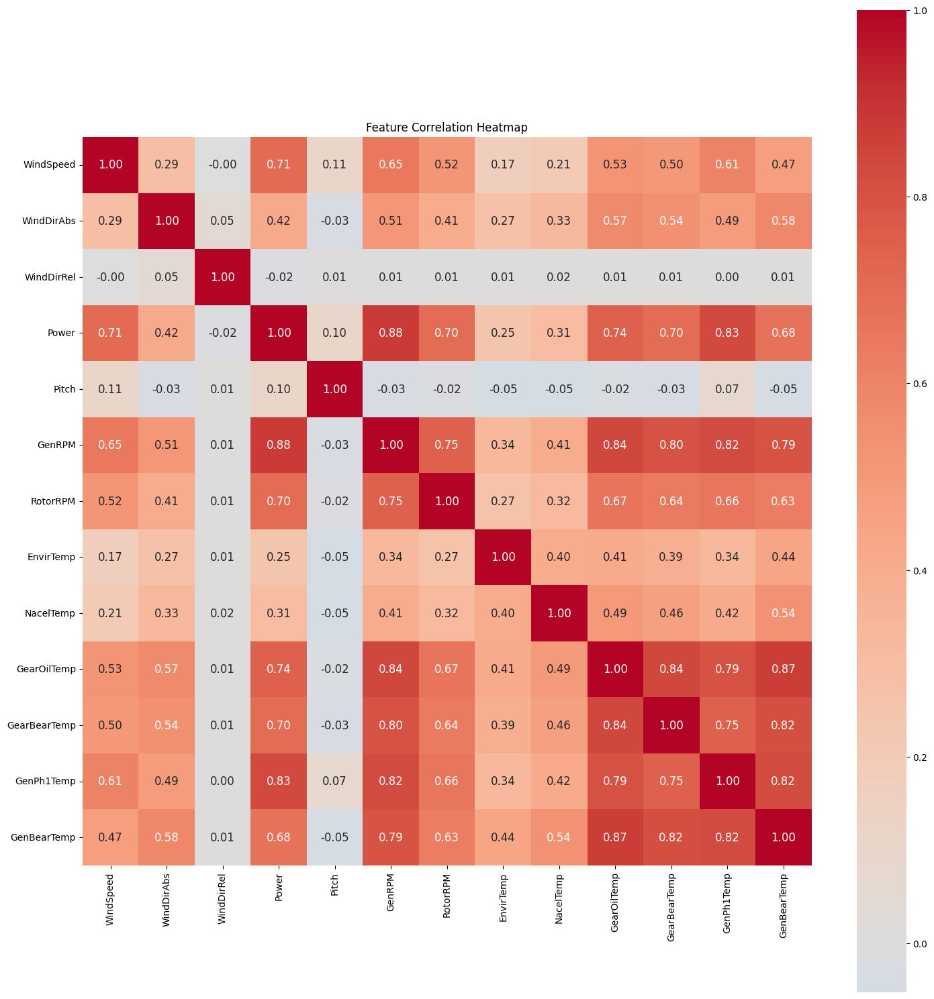

In [13]:
# Compute correlation matrix
corr = df.corr()

# Plot heatmap with annotations
plt.figure(figsize=(15, 15))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    annot_kws={"size": 12},
)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()

- We see that some parameters have VERY good correlations like Power <--> GenRPM corr=0.88
- Some parameters are barely correlated with anything, e.g. Pitch.
- There are many moderate to strong correlation values.
- What is weird is that when we analyze timeseries, we did NOT see such strong relationships, especially taking into account the noise.

Let's take Power as an example and sort correlations from highest to lowest.

In [14]:
# Compute correlation of all columns with the target
corr = df.corr()["Power"].drop("Power")

# Sort by absolute correlation value
correlations_sorted = corr.reindex(corr.abs().sort_values(ascending=False).index)
correlations_sorted

GenRPM          0.879374
GenPh1Temp      0.828008
GearOilTemp     0.743265
WindSpeed       0.705276
RotorRPM        0.703314
GearBearTemp    0.703189
GenBearTemp     0.677292
WindDirAbs      0.419142
NacelTemp       0.313068
EnvirTemp       0.249844
Pitch           0.104456
WindDirRel     -0.015779
Name: Power, dtype: float64

From the Time Series plots, we haven't seen such a strong correlation. Let's check the scatter-like plots.

In [15]:
def plot_relationships(
    x: pd.Series, y: pd.Series, x_label: str = "X", y_label: str = "Y"
):
    """
    Plots x-y relationships in different formats (Regression, KDE and HexBin plots)
    """
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Regression Plot (via seaborn)
    sns.regplot(x=x, y=y, ax=axs[0], scatter_kws={"s": 20}, line_kws={"color": "red"})
    axs[0].set_title("Regression Plot")
    axs[0].set_xlabel(x_label)
    axs[0].set_ylabel(y_label)

    # 2. KDE Plot (Seaborn joint density)
    sns.kdeplot(x=x, y=y, fill=True, cmap="mako", ax=axs[1], thresh=0.01)
    axs[1].set_title("KDE Plot")
    axs[1].set_xlabel(x_label)
    axs[1].set_ylabel(y_label)

    # 3. Hexbin Plot (via Matplotlib)
    axs[2].hexbin(x, y, gridsize=30, cmap="viridis", mincnt=1)
    axs[2].set_title("Hexbin Plot")
    axs[2].set_xlabel(x_label)
    axs[2].set_ylabel(y_label)

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

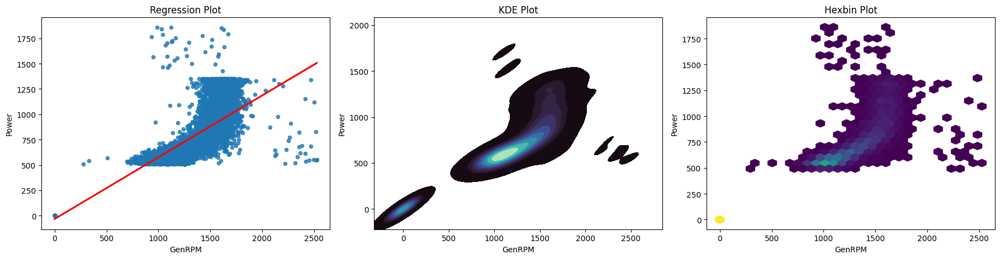

In [16]:
v1 = "GenRPM"
v2 = "Power"
n = 10
df_local = df.copy()  # df[(df[v1] > 800)]
plot_relationships(df_local[v1][::n], df_local[v2][::n], v1, v2)

These variables do NOT look like well-correlated.

The correlation value is strongly effected by the outliers. But in this case making it high!

For the outliers, we can see that there are some clouds of points which are separated from the main relationship.

There is a big cloud of points around zero which drives big correlation.

Let's check for some more variables.

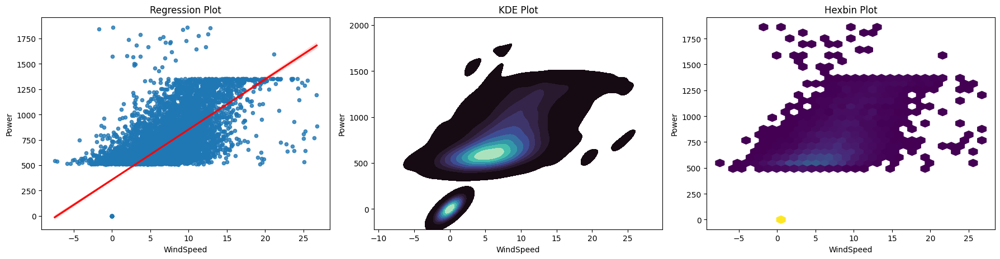

In [17]:
v1 = "WindSpeed"
v2 = "Power"
n = 10
df_local = df.copy()
plot_relationships(df_local[v1][::n], df_local[v2][::n], v1, v2)

We see the same picture here. We also see that there are MANY points that looks like one point in zero. 

This is NOT possible to see in the scatter plot, but we can see it in the KDE and Hexbin plots.

We clearly see that the correlation values are strongly influecned by the outliers, especially zeros.

Let's first remove zeros.

In [18]:
df_no_zero = df[df["Power"] > 20]

In [19]:
# Compute correlation of all columns with the target
corr = df_no_zero.corr()["Power"].drop("Power")

# Sort by absolute correlation value
correlations_sorted = corr.reindex(corr.abs().sort_values(ascending=False).index)
correlations_sorted

GenRPM          0.743865
GenPh1Temp      0.623438
WindSpeed       0.583515
RotorRPM        0.435131
GearOilTemp     0.329779
GearBearTemp    0.241940
Pitch           0.210732
NacelTemp      -0.116867
EnvirTemp      -0.109846
GenBearTemp     0.094865
WindDirRel     -0.030650
WindDirAbs     -0.028678
Name: Power, dtype: float64

Previous correlation values:

In [20]:
# GenRPM          0.879374
# GenPh1Temp      0.828008
# GearOilTemp     0.743265
# WindSpeed       0.705276
# RotorRPM        0.703314
# GearBearTemp    0.703189
# GenBearTemp     0.677292
# WindDirAbs      0.419142
# NacelTemp       0.313068
# EnvirTemp       0.249844
# Pitch           0.104456
# WindDirRel     -0.015779

Now we see much smaller correlations.

Let's check how it looks in scatters.

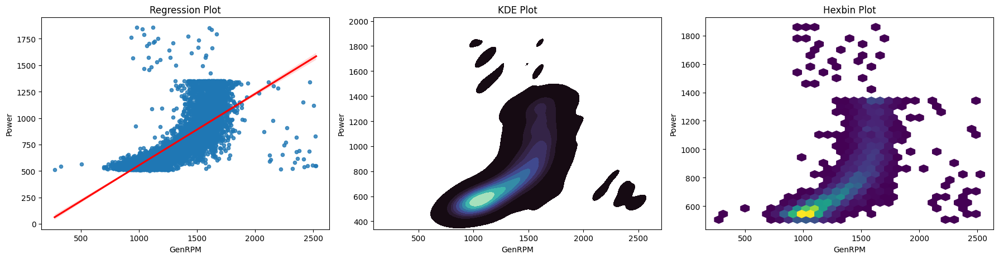

In [21]:
v1 = "GenRPM"
v2 = "Power"
n = 10
df_local = df_no_zero.copy()
plot_relationships(df_local[v1][::n], df_local[v2][::n], v1, v2)

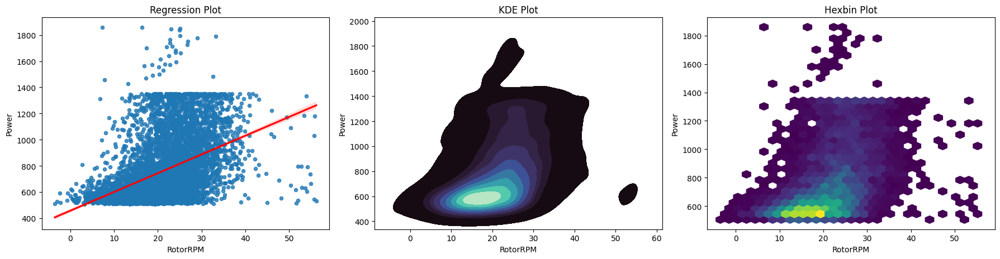

In [22]:
v1 = "RotorRPM"
v2 = "Power"
n = 10
df_local = df_no_zero.copy()
plot_relationships(df_local[v1][::n], df_local[v2][::n], v1, v2)

We still see the influence by the outlers. 
    
And now it's hard to say if the outliers increase or decrease correlations.

But what is more important, it's hard to see the relationships clearly and trully understand the data.

Let's check the distributions more closely.

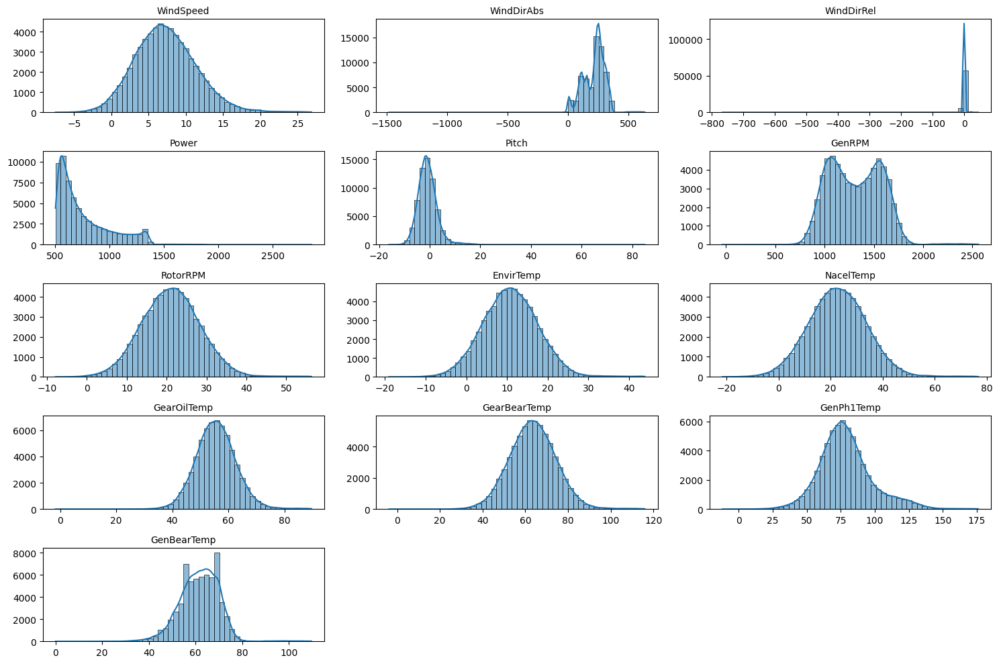

In [23]:
# Select numeric columns only
n_cols = 3
n_rows = int(np.ceil(len(df.columns) / n_cols))

plt.figure(figsize=(15, 10))

for i, col in enumerate(df.columns, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.histplot(df_no_zero[col].dropna(), bins=50, kde=True)
    plt.title(col, fontsize=10)
    plt.xlabel("")
    plt.ylabel("")

plt.tight_layout()

We can see long tails in most of the features, but the number of data points is not that big.

Let's also check if we can see in the multidimentional space reduced to 2 dimentions with PCA.

In [24]:
# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)  # df_no_zero

In [25]:
# Apply PCA
pca = PCA(n_components=len(df.columns))
X_pca = pca.fit_transform(X_scaled)

# Create DataFrame of first 2 components
pca_df = pd.DataFrame(data=X_pca[:, :2], columns=["PC1", "PC2"])

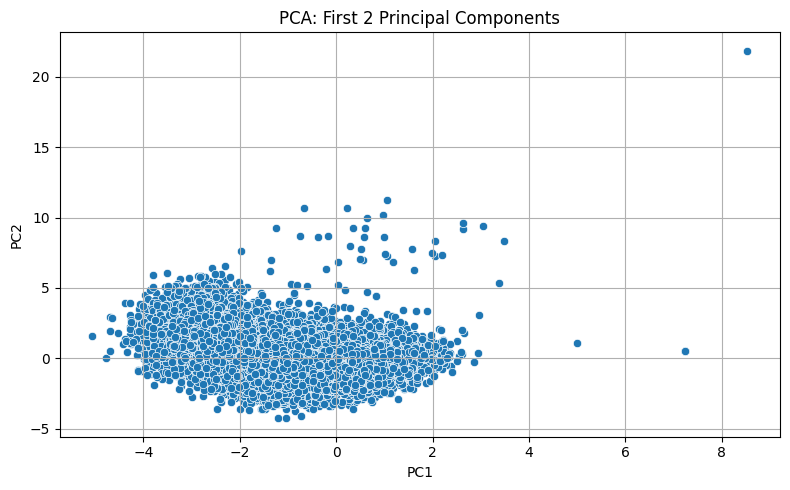

In [26]:
# Plot 1: PCA Scatter Plot (2D)
plt.figure(figsize=(8, 5))
sns.scatterplot(x="PC1", y="PC2", data=pca_df[::1])
plt.title("PCA: First 2 Principal Components")
plt.grid(True)
plt.tight_layout()
plt.show()

We can see that there are outlying values.

If we check this for **df_no_zero**, we will not see them.

So, this means that these PCA outlying values are zeros.

Also, let's check how representative the first two principal components are.

In [27]:
# Plot 2: Explained Variance (Scree Plot)
explained_variance = pca.explained_variance_ratio_
cumulative_variance = explained_variance.cumsum()
cumulative_variance

array([0.52381165, 0.62132262, 0.69894681, 0.77088431, 0.82422704,
       0.86973915, 0.90670569, 0.93763931, 0.95745395, 0.97378272,
       0.9857866 , 0.99382904, 1.        ])

In [28]:
explained_variance

array([0.52381165, 0.09751097, 0.07762419, 0.0719375 , 0.05334273,
       0.04551211, 0.03696654, 0.03093362, 0.01981465, 0.01632876,
       0.01200388, 0.00804244, 0.00617096])

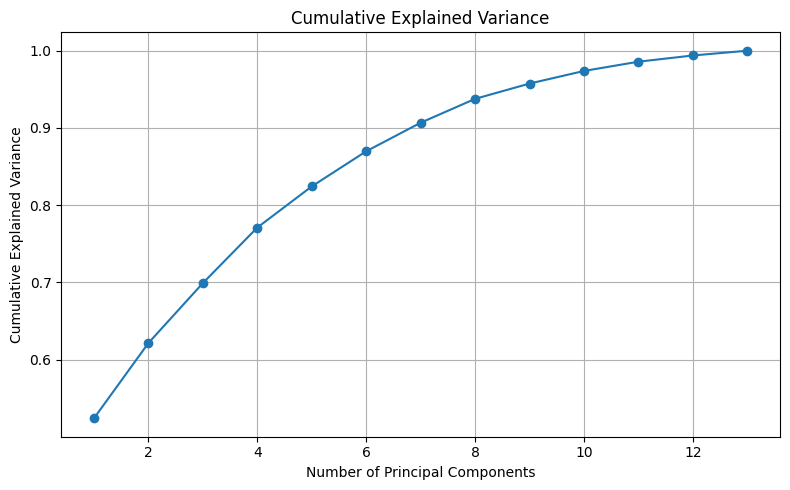

In [29]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o",
    linestyle="-",
)
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")
plt.grid(True)
plt.tight_layout()
plt.show()

Also, we see that a lot of information missing, so overall, PCA plots might not be very representative.

It allowed us to detect only the most obvious "outliers" (which are zeros) which we cleaned easily anyway.

This again emphasize the noisy nature of the data. In the multidimentional space, even the obvious outliers are hard to detect.

In this case, the best way to clean them is feature by feature.

Let's do this.

# Data Cleaning and Grouping

### Z-Score Filter

Let's try to remove the outliers with a simple Z-score filter

In [30]:
def remove_outliers_zscore(
    df: pd.DataFrame, threshold: float = 3, nan_treatment: str = "ffill"
):
    """
    Replace outliers (based on z-score) with NaN for each numeric column
    and report how many values were replaced.

    Parameters
    ----------
    df : pd.DataFrame
        Input DataFrame (numeric or mixed).
    threshold : float, optional
        Z-score threshold. Default = 3.
    nan_treatment: str
        The way we treat nans (ffill or drop)
    Returns
    -------
    df_masked : pd.DataFrame
        DataFrame with outlier values replaced by NaN.
    """
    df_masked = df.copy()
    numeric_cols = df.select_dtypes(include=np.number).columns

    total_replaced = 0
    replaced_per_column = {}

    for col in numeric_cols:
        mean = df[col].mean()
        std = df[col].std(ddof=0)
        z_score = np.abs((df[col] - mean) / std)

        outlier_mask = z_score > threshold
        n_replaced = outlier_mask.sum()

        df_masked.loc[outlier_mask, col] = np.nan

        replaced_per_column[col] = n_replaced
        total_replaced += n_replaced

    # Treat outliers
    if nan_treatment == "ffill":
        df_masked = df_masked.ffill()
    elif nan_treatment == "drop":
        df_masked = df_masked.dropna()
    else:
        raise ValueError(f"{nan_treatment} nan_treatment is not recognized")

    print(f"Replaced {total_replaced} values total (|z| > {threshold}).")
    print("Per column replacements:")
    for col, n in replaced_per_column.items():
        print(f"  {col}: {n}")

    return df_masked

In [31]:
df_clean = remove_outliers_zscore(
    df_no_zero, nan_treatment="ffill", threshold=3
)  # Check with 2-3

Replaced 5607 values total (|z| > 3).
Per column replacements:
  WindSpeed: 449
  WindDirAbs: 309
  WindDirRel: 356
  Power: 279
  Pitch: 723
  GenRPM: 329
  RotorRPM: 367
  EnvirTemp: 400
  NacelTemp: 393
  GearOilTemp: 516
  GearBearTemp: 409
  GenPh1Temp: 499
  GenBearTemp: 578


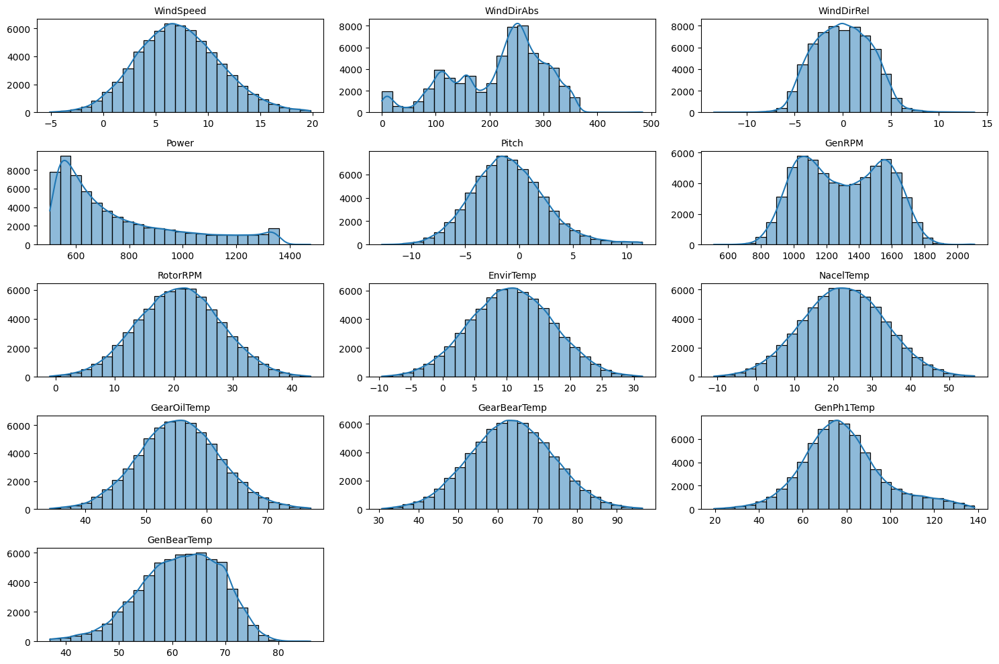

In [32]:
# Select numeric columns only
n_cols = 3
n_rows = int(np.ceil(len(df.columns) / n_cols))

plt.figure(figsize=(15, 10))

for i, col in enumerate(df.columns, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.histplot(df_clean[col].dropna(), bins=25, kde=True)
    plt.title(col, fontsize=10)
    plt.xlabel("")
    plt.ylabel("")

plt.tight_layout()

We see that we cut the outliers quite well. Now, let's check the X-Y plots.

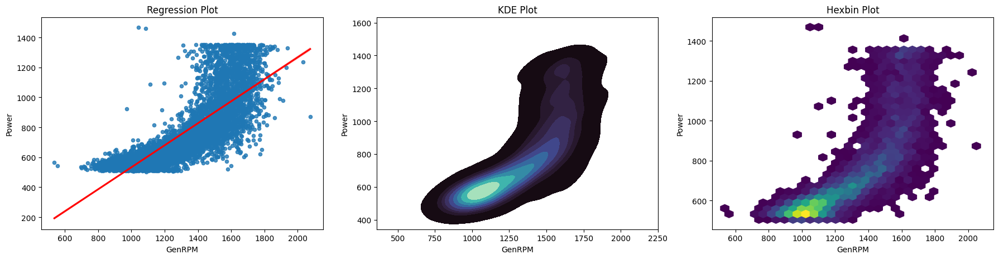

In [33]:
v1 = "GenRPM"
v2 = "Power"
n = 10
df_local = df_clean.copy()
plot_relationships(df_local[v1][::n], df_local[v2][::n], v1, v2)

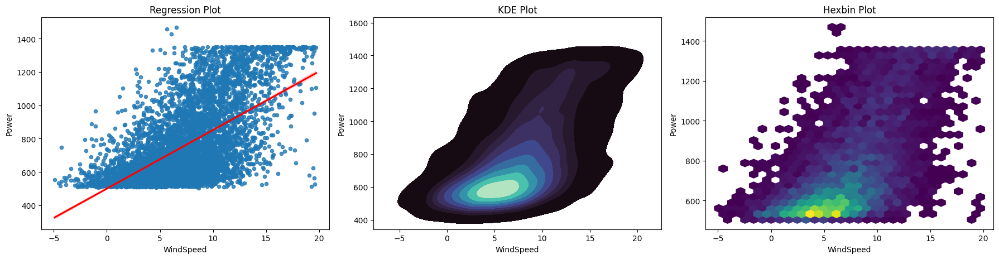

In [34]:
v1 = "WindSpeed"
v2 = "Power"
n = 10
df_local = df_clean.copy()
plot_relationships(df_local[v1][::n], df_local[v2][::n], v1, v2)

Now, we can better see the relationships. 

However, due to the noisy nature of the signals, it's still hard.

Let's try one trick - let's plot grouped data.

## Grouped data plots

In [35]:
df_gr = df_clean.resample("6h").mean()

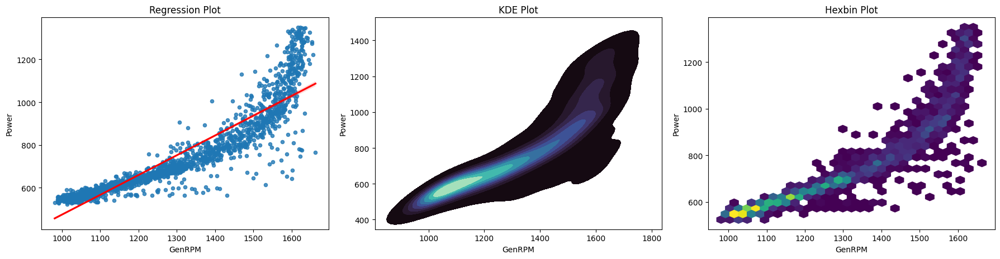

In [36]:
v1 = "GenRPM"
v2 = "Power"
n = 1
df_local = df_gr.copy()
plot_relationships(df_local[v1][::n], df_local[v2][::n], v1, v2)

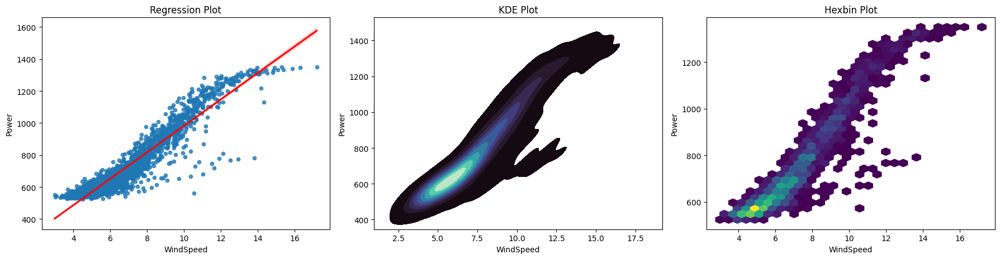

In [37]:
v1 = "WindSpeed"
v2 = "Power"
n = 1
df_local = df_gr.copy()
plot_relationships(df_local[v1][::n], df_local[v2][::n], v1, v2)

Plotting: WindSpeed vs Power


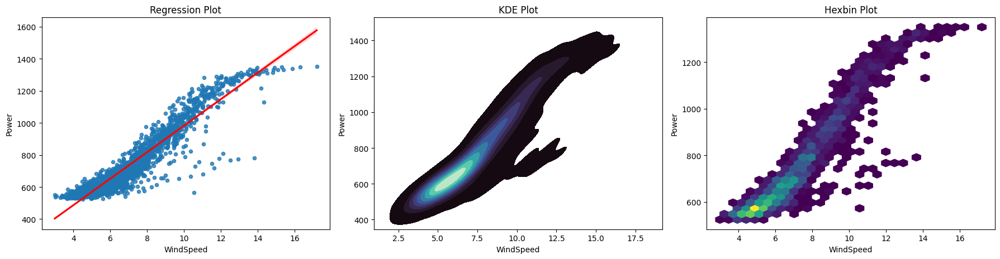

Plotting: WindDirAbs vs Power


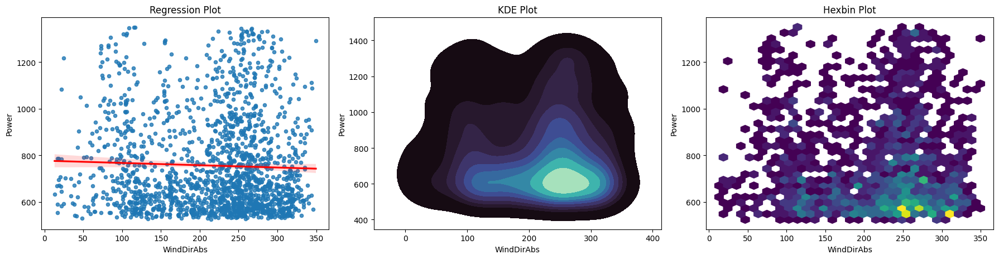

Plotting: WindDirRel vs Power


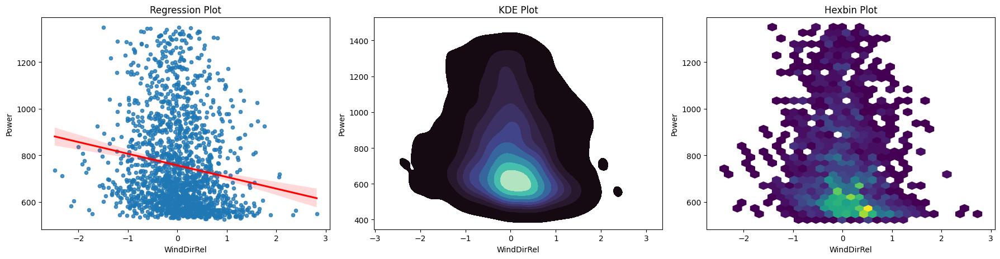

Plotting: Pitch vs Power


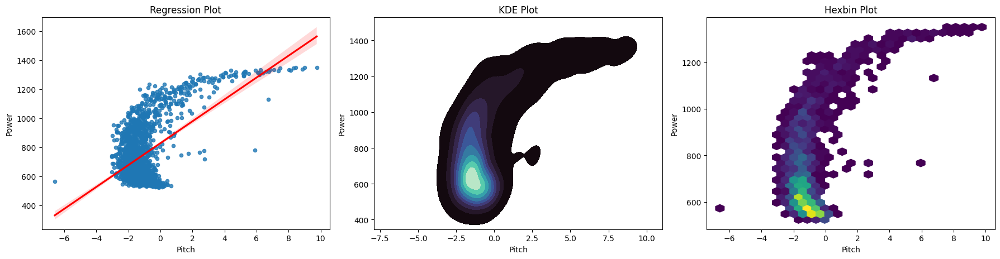

Plotting: GenRPM vs Power


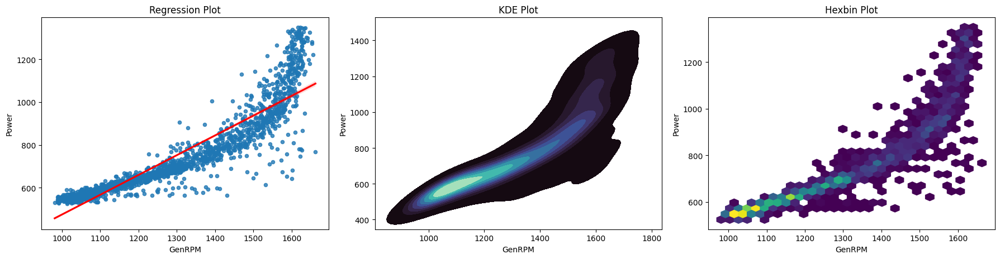

Plotting: RotorRPM vs Power


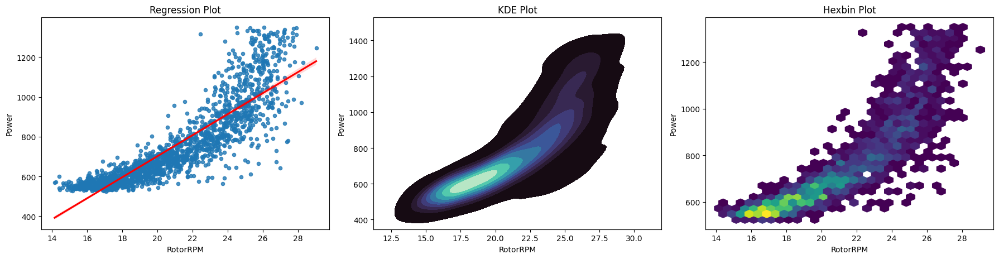

Plotting: EnvirTemp vs Power


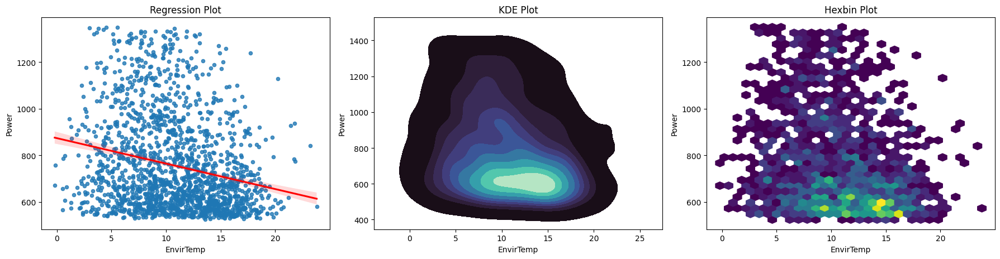

Plotting: NacelTemp vs Power


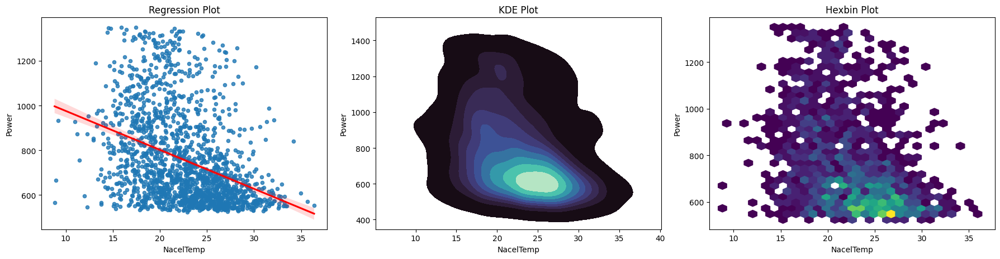

Plotting: GearOilTemp vs Power


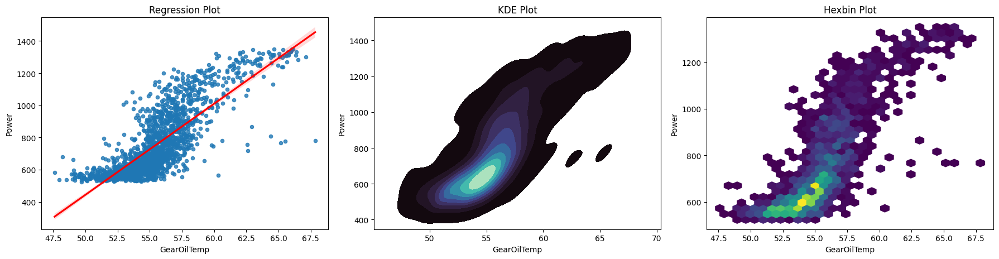

Plotting: GearBearTemp vs Power


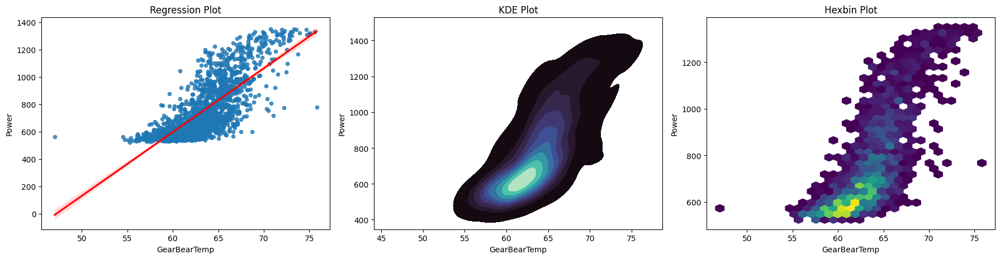

Plotting: GenPh1Temp vs Power


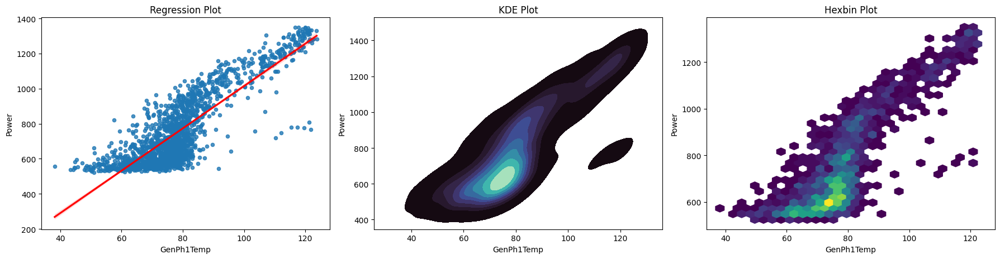

Plotting: GenBearTemp vs Power


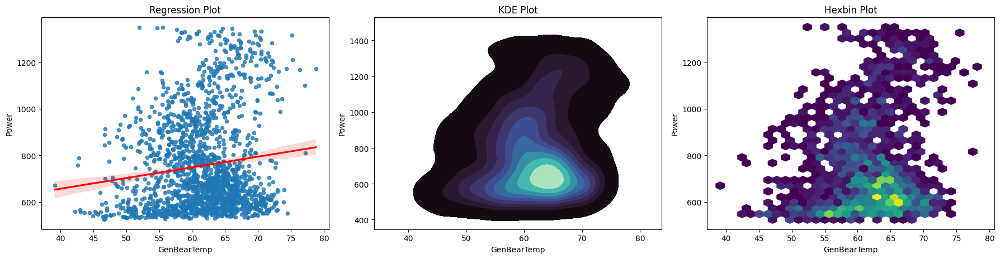

In [38]:
v2 = "Power"  # fixed y-variable
df_local = df_gr.copy()
n = 1  # subsampling step

for col in df_local.columns:
    if col == v2:
        continue  # skip Power itself
    print(f"Plotting: {col} vs {v2}")
    plot_relationships(df_local[col][::n], df_local[v2][::n], col, v2)

Now we can see that ON AVERAGE for some variables like WindSpeed or GenRPM vs Power the relationships are quite linear.

We can take this into account because maybe it can be useful when creating the model and identifying the time horizon for the model prediction.

Some varibleas are close to linear dependency, but the variance is very high, e.g. EnvirTemp vs Power.

Pitch has a very strange relationship with Power, however, in some data ranges it can be a useful predictor.

Let's see how it looks as a time series.

In [39]:
cols_to_plot = [
    "Power",
    "WindSpeed",
    "GenRPM",
    "RotorRPM",
    "WindDirAbs",
    "WindDirRel",
    "Pitch",
    "EnvirTemp",
    "NacelTemp",
    "GearOilTemp",
    "GearBearTemp",
    "GenPh1Temp",
    "GenBearTemp",
]

plot_time_series(df_gr, cols_to_plot, step=1)

We can see and study the time series more clearly after grouping.

We can see how big ups and downs for high correlation features match ups and downs of Power.

However, we can't really see any specific behavior before the the downtime.

Let's try to do something simple - apply PCA to the grouped data.

The idea is that if there is a region in a multidimentional space that is abnormal to the main cloud of points, this might correspond to the anomaly behavior that we want to see.

We saw that on the original data it did not work but it can be because of the high noise in the data.

### PCA on Grouped Data

In [40]:
df_pca = df_gr.copy().dropna()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_pca)

pca = PCA(n_components=len(df_pca.columns))
X_pca = pca.fit_transform(X_scaled)


pca_df = pd.DataFrame(data=X_pca[:, :2], index=df_pca.index, columns=["PC1", "PC2"])

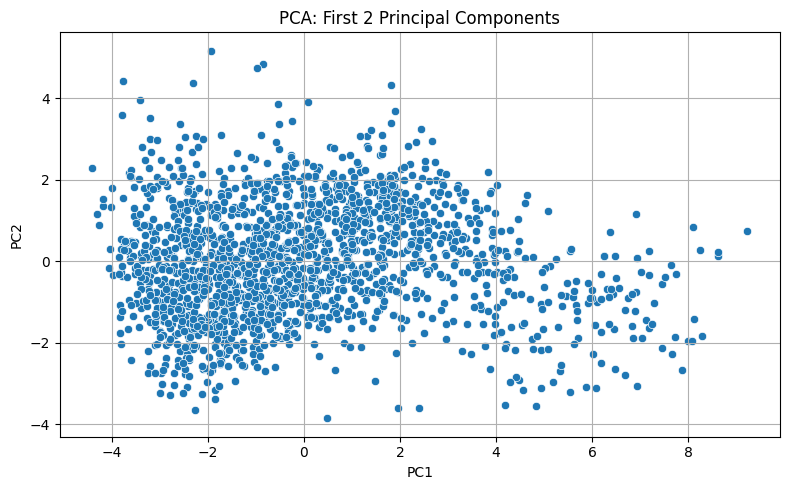

In [41]:
# Plot 1: PCA Scatter Plot (2D)
plt.figure(figsize=(8, 5))
sns.scatterplot(x="PC1", y="PC2", data=pca_df[::1])
plt.title("PCA: First 2 Principal Components")
plt.grid(True)
plt.tight_layout()
plt.show()

In [42]:
# Plot 2: Explained Variance (Scree Plot)
explained_variance = pca.explained_variance_ratio_
cumulative_variance = explained_variance.cumsum()
cumulative_variance

array([0.49442093, 0.64301688, 0.72420927, 0.80232116, 0.86986744,
       0.93040683, 0.95552772, 0.9711166 , 0.98100581, 0.98862526,
       0.99352813, 0.99766723, 1.        ])

- We see that even after grouping, first 2 PC still do not explain eniough of variance.
- We can see some "cluster" of points for PC_1 > 4, but it's not very well separated.
- However, let's plot it on time series.

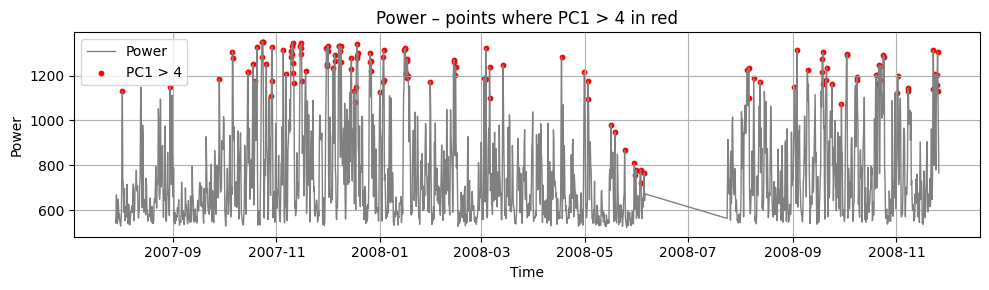

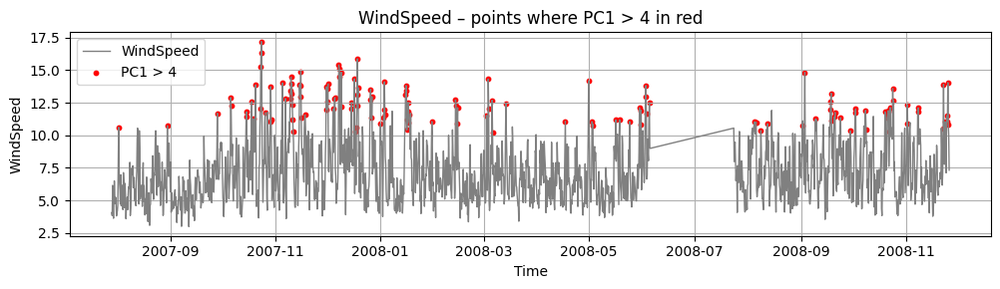

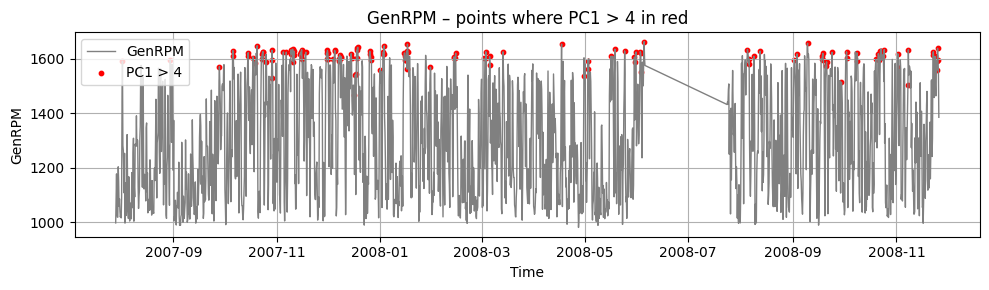

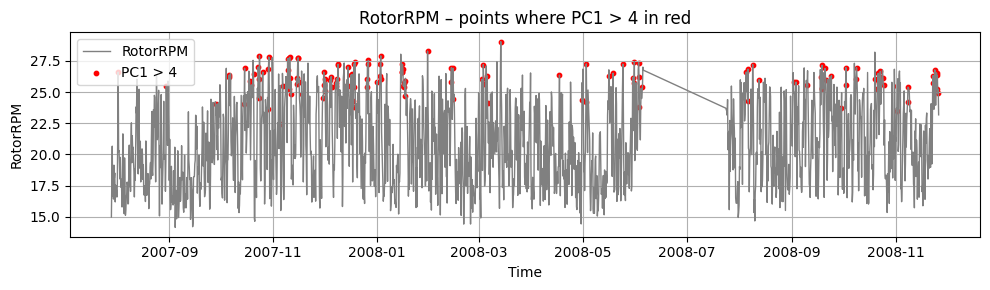

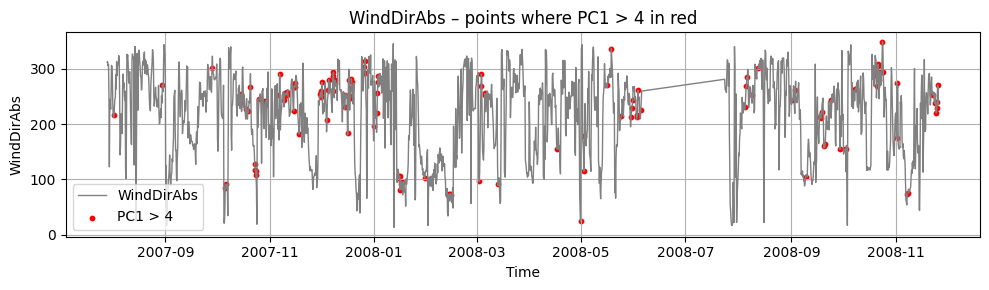

...

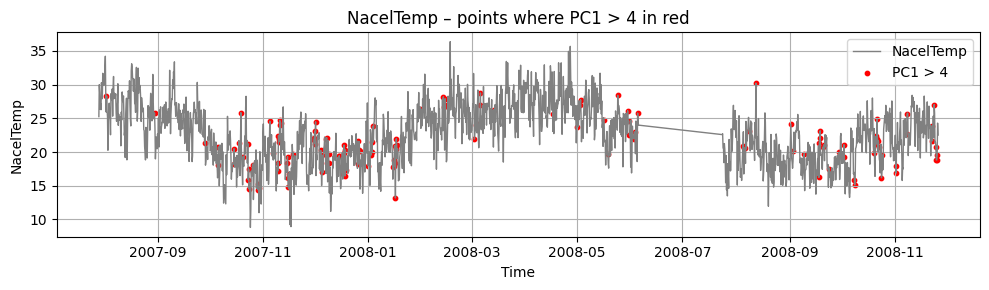

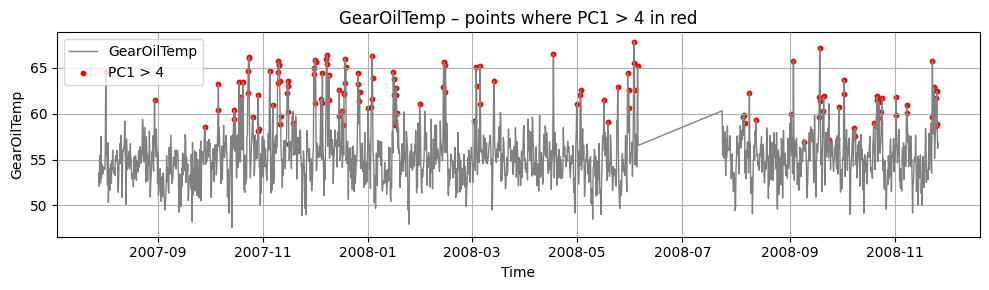

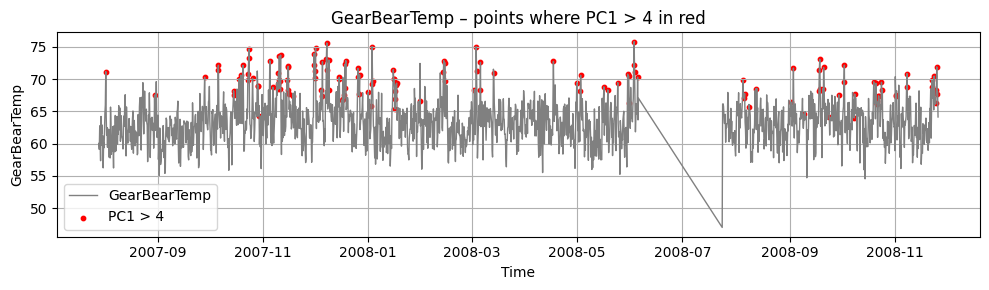

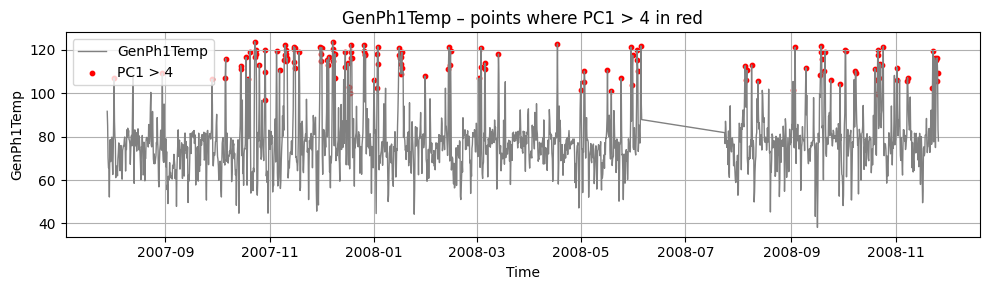

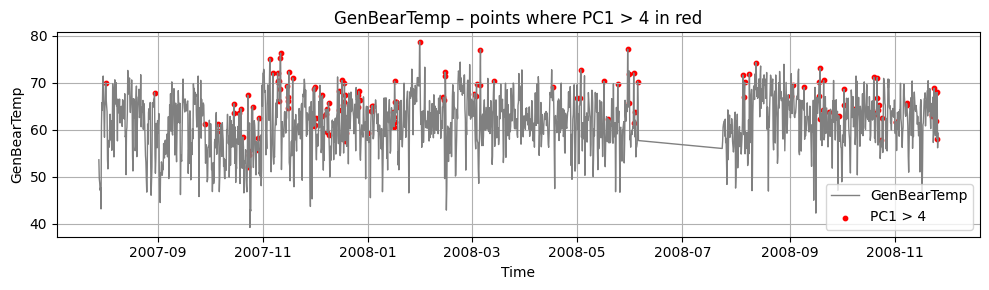

In [43]:
pc1_thr = 4
pc1 = pca_df["PC1"]

mask_red = pc1 > pc1_thr  # positions where PC1 is "high"

cols_to_plot = [
    "Power",
    "WindSpeed",
    "GenRPM",
    "RotorRPM",
    "WindDirAbs",
    "WindDirRel",
    "Pitch",
    "EnvirTemp",
    "NacelTemp",
    "GearOilTemp",
    "GearBearTemp",
    "GenPh1Temp",
    "GenBearTemp",
]

for col in cols_to_plot:
    plt.figure(figsize=(10, 3))

    # base time series (grey line)
    plt.plot(df_pca.index, df_pca[col], color="grey", linewidth=1, label=col)

    # mark PC1 > threshold in red
    plt.scatter(
        df_pca.index[mask_red],
        df_pca.loc[mask_red, col],
        color="red",
        s=10,
        label=f"PC1 > {pc1_thr}",
    )

    plt.title(f"{col} – points where PC1 > {pc1_thr} in red")
    plt.xlabel("Time")
    plt.ylabel(col)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

- We see that PCA "outliers" are just the points with highest values of Power, WindSpeed, GenRPM, etc.
- We see that these values happened far before the downtime and quite quickly after downtime.
- So, these points can hardly be considered as anomalies in terms of downtime detection.

# What we achieved and what is the problem

- We understand that the data has a lot of noise that can be averaged out.
- We understand the main relationships between the parameters.
- We can clean only basic "outlier / anomaly" regime - when the tuurbine is stopped.
- We do not see strong anomaly behavior in 1D (per feature) close to downtime.
- We do not see any anomaly identified via PCA, both on averaged and on raw data.
- **We still don't know if (and how) we can identify the anomaly behavior consistenly**

# Mahalanobis distance study to identify anomaly region

Mahalanobis Distance measures how far a point is from the center of a multivariate distribution while accounting for correlations between features.

Unlike Euclidean distance, it adjusts for:
- different variances in each feature
- correlations between features
- scale differences across dimensions


Mahalanobis Distance is defined as:

$$
D_M(x) = \sqrt{(x - \mu)^T \Sigma^{-1} (x - \mu)}
$$

Where:

- $x$ is the data point  
- $\mu$ is the mean vector  
- $\Sigma^{-1}$ is the inverse covariance matrix

A covariance matrix is a table that shows how features vary together.


\begin{aligned}
\Sigma
&=
\begin{bmatrix}
\mathrm{Var}(x_1) & \mathrm{Cov}(x_1,x_2) & \cdots & \mathrm{Cov}(x_1,x_d) \\
\mathrm{Cov}(x_2,x_1) & \mathrm{Var}(x_2) & \cdots & \mathrm{Cov}(x_2,x_d) \\
\vdots & \vdots & \ddots & \vdots \\
\mathrm{Cov}(x_d,x_1) & \mathrm{Cov}(x_d,x_2) & \cdots & \mathrm{Var}(x_d)
\end{bmatrix}
\end{aligned}

The covaraince between 2 variables:

$$
\mathrm{cov}(x_i,x_j)=\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x_i})(x_j-\bar{x_j})
$$

**Mahalanobis Distance answers:**

"How many multivariate standard deviations away is this point from the center?"

In [44]:
# 1) Split
split_point = 30000  # these points are assumed to be "Normal"
df_mah_train = df_clean.iloc[:split_point].dropna().copy()
df_mah_test = df_clean.iloc[split_point:].dropna().copy()

# 2) Arrays
x_train = df_mah_train.values
x_test = df_mah_test.values

# 4) Covariance
mu = np.mean(x_train, axis=0)
cov = np.cov(x_train, rowvar=False)
cov_inv = np.linalg.pinv(cov)

# 5) Mahalanobis
diff = x_test - mu
mah_components = (diff @ cov_inv) * diff

dist = np.sum(mah_components, axis=1)
df_mah_test["mahalanobis_distance"] = np.sqrt(dist)

In [45]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=df_mah_test.index,
        y=df_mah_test["mahalanobis_distance"],
        mode="lines",
        name="Mahalanobis distance",
    )
)

fig.add_trace(
    go.Scatter(
        x=df_mah_test.index,
        y=df_mah_test["mahalanobis_distance"].rolling(50).median(),
        mode="lines",
        name="Rolling median (50)",
        line=dict(color="black", width=2),
    )
)

fig.update_layout(
    title="Mahalanobis distance (test segment)",
    xaxis_title="Time",
    yaxis_title="Distance",
    template="plotly_white",
    legend=dict(
        x=0.01,
        y=0.99,
        xanchor="left",
        yanchor="top",
        bgcolor="rgba(255,255,255,0)",
        bordercolor="rgba(0,0,0,0)",
        font=dict(size=11),
        orientation="h",
    ),
)

fig.show()

- Finally, we can see some anomaly signs around the downtime.
- Around the end of May, the distance starts rising quite a lot. This indicates that these data points are gettung away from the normal range INCLUDING the covariance between the features.
- So, the main conclusion is that THERE ARE some anomalies around the downtime.
- It's tempting to use Mahalanobis distance to monitor anomaly in production, however, this method can be numerically unstable and not robust to noise.
- Also, we do not really understand which parameters influenced the distance (and the Turbine) to behave abnormally.

Let's try to explain what contribute the most to the Mahalanobis distance rise.

### Understand of feature MD contribution to the overall MD.

One option to see the contribution of each feature to the overall Mahalanobis distance (MD) is fit an ML model where target is the Mahalanobis distance and features are MD for each raw feature.

Let's fit a CatBoost model with default parameters.

In [46]:
df_mah_components = pd.DataFrame(
    mah_components, columns=df_mah_train.columns, index=df_mah_test.index
)
df_mah_components.head(5)

,WindSpeed,WindDirAbs,WindDirRel,Power,Pitch,GenRPM,RotorRPM,EnvirTemp,NacelTemp,GearOilTemp,GearBearTemp,GenPh1Temp,GenBearTemp
Timestamps,,,,,,,,,,,,,
2008-02-22 11:10:00,5.128911,0.505913,1.913487,-0.164178,0.171337,-0.058719,1.791667,0.342456,2.200055,0.140061,0.677382,0.074468,4.047901
2008-02-22 11:20:00,1.826511,0.474450,0.050299,0.857655,-0.036926,-0.379633,0.216284,0.766545,0.336655,1.583112,0.208916,0.001517,3.373284
2008-02-22 11:30:00,0.678194,0.563862,0.121889,0.253693,1.735913,1.540233,0.553602,0.753760,-0.098238,0.390107,1.221555,1.035824,2.550221
2008-02-22 11:40:00,-0.115676,0.638051,-0.000361,-2.342663,1.319852,4.112682,-0.079734,-0.017066,0.458275,1.685890,0.219341,2.636379,5.876964
2008-02-22 11:50:00,0.392303,0.591972,0.479025,-2.000483,0.606178,9.925864,0.159622,2.014420,-0.084835,0.125270,1.938457,0.022891,3.570800


In [47]:
# Use true per-feature Mahalanobis contributions as model features
df_contrib_all = pd.DataFrame(
    mah_components, index=df_mah_test.index, columns=df_mah_train.columns
)

X = df_contrib_all
y = df_mah_test["mahalanobis_distance"]

# Train CatBoost on all test data
# (Model learns mapping: per-feature-contrib → anomaly score)

model = CatBoostRegressor(
    depth=6,
    learning_rate=0.05,
    iterations=600,
    loss_function="RMSE",
    verbose=False,
    random_seed=42,
)

model.fit(X, y)

CatBoostRegressor(depth=6, iterations=600, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=False)

Now, let's try to use SHAP values.

We will check SHAP values for anomaly data - Mahalanobis distace > 4.5

In [48]:
# Select anomaly subset
threshold = 4.5
anom_mask = y >= threshold

X_anom = X[anom_mask]
y_anom = y[anom_mask]

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_anom)  # explain anomalies only

# Global ranking
shap_importance = np.abs(shap_values).mean(axis=0)
shap_ranking = pd.Series(shap_importance, index=X.columns).sort_values(ascending=False)

print("\nSHAP Feature Importance (Anomaly Region):")
print(shap_ranking)


SHAP Feature Importance (Anomaly Region):
Power           0.344023
GenRPM          0.335284
GenPh1Temp      0.332417
WindSpeed       0.222030
GearOilTemp     0.197823
EnvirTemp       0.193429
GearBearTemp    0.192666
RotorRPM        0.190961
Pitch           0.185867
WindDirRel      0.182343
NacelTemp       0.180545
GenBearTemp     0.146270
WindDirAbs      0.136079
dtype: float64


Let's also plot the summary SHAP values plot.

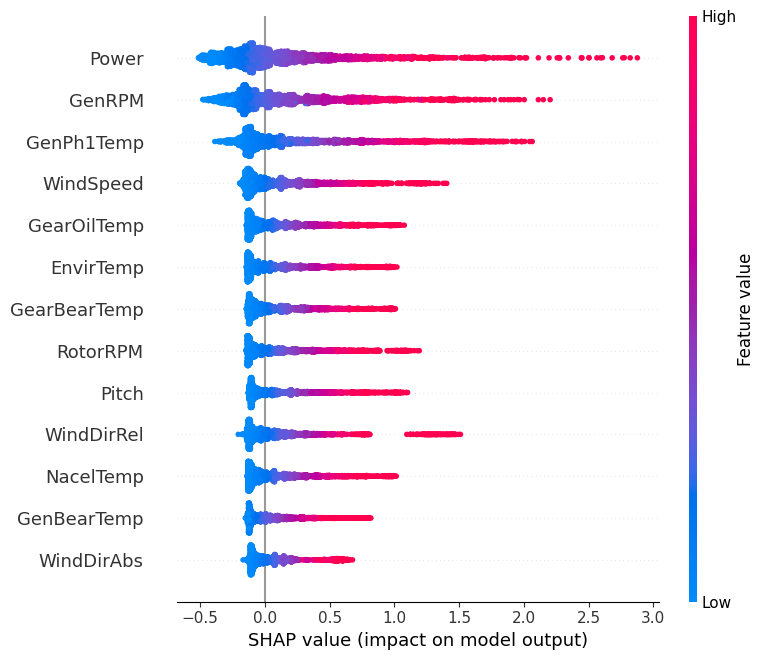

In [49]:
shap.summary_plot(shap_values, X_anom)

From the plot we see that (very logically) that as MD per feature encreases, the overall MD increases.

The most contributing parameter is the Power, both to negative and positive directions.

This means that by identifying how Power deviates from the "Normal operations" including it's interactions with other parameters, we can potentially detect anomaly behavior of the wind turbine.

## Mahalanobis distance and SHAP values study conclusions

- We identified that based on the Mahalanobis distance approach, it's possible to detect that there's a clear anomaly trend close to the turbine downtime.
- We identified that Power, GenRPM and GenPh1TEmp controbute the most to the anomalious region.
- When using the SHAP values explainer of a CatBoost model, Power feature dominates.
- From the technological perspective, Power is the resulting variable from the Wind Turbine work.
- Mahalanobis distance itself can be used to detect the anomaly region and to solve the business problem that we have.
- However, this method can be numerically unstable.
- **From both data-driven approach and technological point of view, it's proposed to monitor Power as the main signal to identify the anomaly using regression models.**

# Noise study

During the entire EDA, we observed that the data seems to have quite a lot of noise, so this section studies the noise in more detail using Fast Fourier Transformations.

FFT (Fast Fourier Transform) is an algorithm that converts a time-series signal into its frequency components.
Instead of looking at how the signal changes over time, FFT shows which frequencies are present and how strong they are.

This is useful because:

- Noise often appears as high-frequency components
- Trends and slow variations appear as low-frequency components
- Periodic behavior becomes clearly visible in the frequency domain

By analyzing the frequency spectrum, we can better understand the underlying structure of the signal and identify which parts of the variation come from meaningful patterns versus random noise.

To quicly get an idea, let's create a signal of 2 sin waves of different frequencies + noise.

We need to define a compute of parameters.

**dt = sampling interval** - The time between two samples, expressed in any unit you choose (seconds, minutes, hours)

If we want to express units is hours and we have data points every 10 mins, we get:

dt = 10 mins / 60 mins = 0.1666 h

**f = Frequency** - Number of cycles per unit time (e.g., per minuite or per hour)

In [50]:
dt = 10 / 60  # 10 minutes in hours
t = np.arange(0, 24, dt)  # 24 hours

freq1 = 0.5  # slow wave
freq2 = 1.5  # fast wave

signal = 3 * np.sin(2 * np.pi * freq1 * t) + 1 * np.sin(2 * np.pi * freq2 * t)

noise = 1.5 * np.random.randn(len(t))

df_demo = pd.DataFrame({"demo_signal": signal + noise})

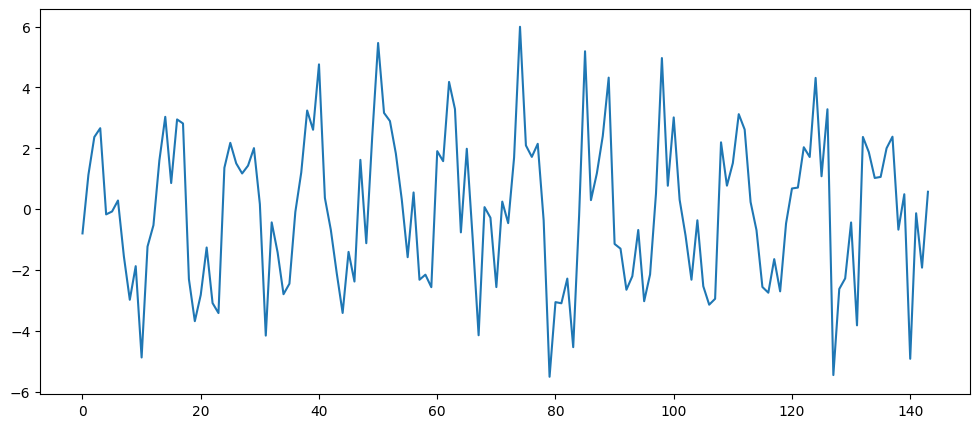

In [51]:
plt.figure(figsize=(12, 5))
plt.plot(df_demo["demo_signal"])

In [52]:
def compute_fft(df: pd.DataFrame, col: str, dt: float = 10 / 60):
    """
    Compute a one-sided FFT-based power spectrum.

    Parameters
    ----------
    df  : DataFrame with the signal
    col : column name (string)
    dt  : sampling interval for the selected unit (e.g. 10/60 for 10 min in hours)
    """
    x_raw = df.loc[:, col].values
    x = x_raw - np.mean(
        x_raw
    )  # remove DC offset (zero-frequency component - mean value)

    N = len(x)

    # Compute the one-sided FFT
    fft_vals = np.fft.rfft(x)

    # Corresponding frequency bins:
    freqs = np.fft.rfftfreq(N, d=dt)

    # Simple power spectrum:
    power = (np.abs(fft_vals) ** 2) / N

    return freqs, power, fft_vals, np.mean(x_raw)

In [53]:
freqs, power, fft_vals, x_mean = compute_fft(df_demo, "demo_signal", dt=dt)

In [54]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(x=freqs, y=power, mode="lines", line=dict(width=2), name="FFT Power")
)

fig.update_layout(
    title="FFT Power Spectrum",
    xaxis_title="Frequency (cycles per hour)",
    yaxis_title="Power",
    height=500,
    width=900,
)

fig.show()

Here, we see that after transforming the signal to the frequency space, we can clearly identify that there are 2 main frequencies in the signal, 0.5 and 1.5.

We can also see that other frequencies are covered with small noise fluctuations.

What is the most beautiful, we can take the inverse transformation and reconstruct the original signal.

In [55]:
x_inverse = (
    np.fft.irfft(fft_vals, n=df_demo.shape[0]) + x_mean
)  # inverse FFT (no filtering)

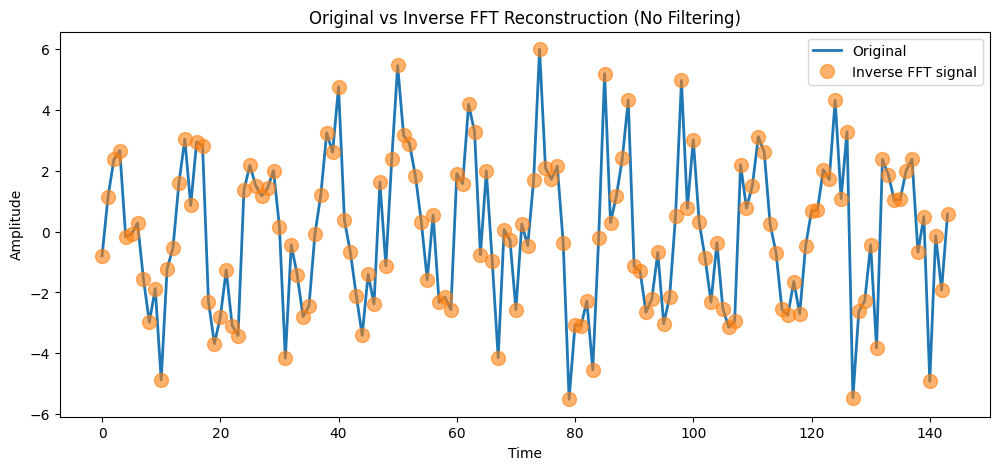

In [56]:
plt.figure(figsize=(12, 5))
plt.plot(df_demo["demo_signal"], label="Original", linewidth=2)
plt.plot(x_inverse, "o", markersize=10, alpha=0.6, label="Inverse FFT signal")
plt.title("Original vs Inverse FFT Reconstruction (No Filtering)")
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.legend()

This gives us the opportunity to denoise the signal.

What we can simply do is we keep only the frequenices (or power spectrum) that we want and cut the rest which we think is noise.

This then can be inverted to the original domain and ideally it should represent the signal with no to little noise.

### Denoising

Before denoising, let's decompose each signal using FFT.

In [57]:
dt = 10 / 60  # 10 minutes in hours (cycles/hour)
fft_dict = {}

for col in df.columns:
    freqs, power, fft_vals, x_mean = compute_fft(df_no_zero, col, dt=dt)
    fft_dict[col] = {"freqs": freqs, "power": power}

In [58]:
col = "WindSpeed"  # pick the column you want

freqs = fft_dict[col]["freqs"]
power = fft_dict[col]["power"]

fig = go.Figure()

fig.add_trace(go.Scatter(x=freqs, y=power, mode="lines", line=dict(width=2), name=col))

fig.update_layout(
    title=f"FFT Power Spectrum: {col}",
    xaxis_title="Freq (cycles/hour)",
    yaxis_title="Power",
    height=500,
    width=900,
    showlegend=False,
)

fig.show()

In [59]:
n_cols = 3
n_plots = len(df.columns)
n_rows = math.ceil(n_plots / n_cols)

fig = make_subplots(
    rows=n_rows,
    cols=n_cols,
    subplot_titles=df.columns,
    vertical_spacing=0.05,
    horizontal_spacing=0.05,
)

# ---- Add each FFT plot ----
for idx, col in enumerate(df.columns):
    row = idx // n_cols + 1
    col_pos = idx % n_cols + 1

    fig.add_trace(
        go.Scatter(
            x=fft_dict[col]["freqs"], y=fft_dict[col]["power"], mode="lines", name=col
        ),
        row=row,
        col=col_pos,
    )

    fig.update_xaxes(title_text="Freq (cycles/hour)", row=row, col=col_pos)
    fig.update_yaxes(title_text="Power", row=row, col=col_pos)


# ---- Set global layout ----
fig.update_layout(
    height=350 * n_rows,
    width=1200,
    showlegend=False,
    title_text="FFT Power Spectra for All Columns",
)

fig.show()

Now, let's create a function that cuts off the frequencies that are above some values. This is called low-pass filter.

In [60]:
def fft_lowpass_filter(x, dt, cutoff):
    """
    Apply a low-pass FFT filter.

    Parameters
    ----------
    x : array-like
        Raw time-series signal.
    dt : float
        Sampling interval in chosen time units (e.g. 10/60 for cycles/hour).
    cutoff : float
        Cutoff frequency in same units as FFT output (e.g. cycles/hour).

    Returns
    -------
    x_filtered : np.array
        Filtered time-series (mean added back).
    freqs : np.array
        Frequency axis.
    fft_filtered : np.array
        Filtered FFT values.
    """

    # Ensure numpy array
    x_clean = np.asarray(x, dtype=float)

    # Detrend (remove mean for FFT)
    x_detrended = x_clean - np.mean(x_clean)

    N = len(x_detrended)

    # FFT
    fft_vals = np.fft.rfft(x_detrended)
    freqs = np.fft.rfftfreq(N, d=dt)

    # Low-pass mask - remove frequences below the cutoff value
    mask = freqs <= cutoff
    fft_filtered = fft_vals * mask

    # Inverse FFT + ADD MEAN BACK
    x_filtered = np.fft.irfft(fft_filtered, n=N) + np.mean(x_clean)

    return x_filtered, freqs, fft_filtered

In [61]:
cutoff = 1.2
col = "WindSpeed"

x = df_no_zero.loc[:, col].values

x_filt, freqs, fft_filt = fft_lowpass_filter(x, dt, cutoff)
df_no_zero.loc[:, col + "_filt"] = x_filt

/var/folders/kj/fc4v0b3d6cx2jngqq9xlbzz40000gn/T/ipykernel_12012/643392585.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_no_zero.loc[:, col + "_filt"] = x_filt


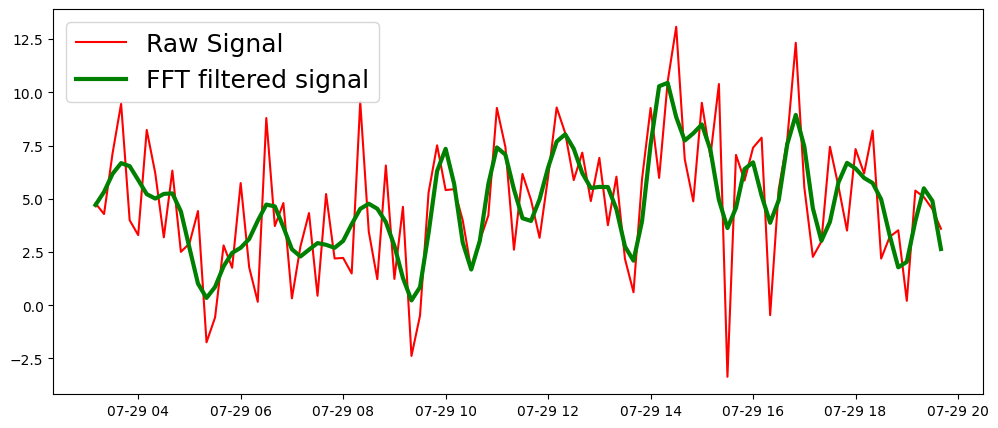

In [62]:
plt.figure(figsize=(12, 5))
plt.plot(df_no_zero[col][:100], label="Raw Signal", color="red")
plt.plot(
    df_no_zero[col + "_filt"][:100], label="FFT filtered signal", color="green", lw=3
)
# plt.plot(df_no_zero[col][:100].rolling(3).mean(), label='Rolling mean signal')
plt.legend(fontsize=18)

Let's compute the correlations before and after filtering.

In [63]:
df_no_zero["Power"].corr(df_no_zero["WindSpeed"])

0.5835145946941264

In [64]:
df_no_zero["Power"].corr(df_no_zero["WindSpeed_filt"])

0.7180250713856284

We see that the correlation improved because we removed the noise from the signal.

This most likely means that the noise level is indeed high in the data and by removing it, we can reconstruct the original signal.

This is a promising approach for data cleaning later and ML model improvement.

There are other filters that we can use to denoise the data, we will see them later when cleaning the data and building the model.

# Conclusions

## Executive Summary

This report analyzes multivariate behavior of a wind turbine using correlations, time-series exploration, PCA, Anomaly analysis (Mahalanobis distance, and model-based explainability (CatBoost + SHAP)) and Noise study.

What we have found is that, despite heavy noise, three variables consistently dominate anomaly formation:

**Key Drivers of Abnormal Behavior**
- GenRPM  
- GenPh1Temp  
- Power  

These features jointly describe mechanical–thermal stress states inside the turbine. Environmental variables (WindSpeed, WindDirAbs/Rel, Pitch) do not explain anomaly formation, indicating faults are internal rather than wind-driven.

**As the next step, it's decided to proceed with modeling Power parameter as the target in a regression model and then analyzing the deviation of the predicted values from the observed values.**

---

# More detailed conclusions.

1. Many parameters contain strong outliers, including negative values and long tails, which must be cleaned before analysis or modeling.

2. Large block of zeros represents full turbine shutdown periods; these distort correlations, PCA structure, and feature distributions, so they must be excluded from relationship analysis.

3. KDE and hexbin plots reveal dense point clouds at zero values that cannot be seen in scatter plots but heavily distort distribution shapes and correlations.

4. Noise is present across many signals, especially temperature and RPM, and visually overwhelms real structure; denoising significantly clarifies relationships.

5. After FFT smoothing, outlier removal and zeros removal, correlations become physically meaningful, showing clearer dependencies between Power, WindSpeed, GenRPM, and RotorRPM. This is also confirmed after resampling the data with daily mean values.

6. Some variables show partially linear relationships with Power (e.g., WindSpeed, GenRPM), while others behave inconsistently (e.g., Pitch), suggesting differing predictive capabilities.

7. Despite noise reduction using median filter, several variables still show high variability even in median values, indicating multiple operational regimes and non-stationarity.

8. PCA reveals outlying values driven primarily by zeros rather than true anomalies, and the first two components do not explain enough variance for reliable representation.

9. PCA applied to grouped data still fails to separate anomalies clearly; high PCA scores correspond mostly to high operational values rather than true abnormal behavior.

10. Time-series inspection shows that ups and downs of highly correlated features follow Power closely, but no clear anomaly pattern appears before shutdowns using raw or grouped data.

11. Mahalanobis distance clearly rises before the downtime, showing true multivariate deviation that includes covariance structure, unlike PCA or raw correlations.

12. Using CatBoost+SHAP values applied to Mahalanobis distance, the same three features dominate anomaly formation: Power, GenRPM, and GenPh1Temp.

13. These three features are correlated, so their dominance likely represents a joint mechanical–thermal stress regime rather than three independent root causes.

14. Outlier and noise removal is essential for reliable modeling because raw data distort the physical relationships between variables; only after cleaning do true dependencies become visible and usable for predictive modeling.

15. Low-pass filtering (FFT cutoff) can be used to isolate the low-frequency structure from high-frequency noise, revealing clearer physical relationships between Power, RPM, and temperature variables and improving the interpretability of correlations and trends.